In [8]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

prices = pd.read_csv(
    "../data/raw/adjusted_prices.csv",
    index_col=0,
    parse_dates=True
)

prices.head()

,DBC,EEM,EFA,GLD,IEF,IWM,QQQ,SPY,TLT,VNQ
Date,,,,,,,,,,
2010-01-04,21.338844,30.194550,34.581207,109.800003,60.299919,51.111221,40.204666,84.368980,54.620056,23.145569
2010-01-05,21.364208,30.413719,34.611683,109.699997,60.564686,50.935452,40.204666,84.592300,54.972801,23.119604
2010-01-06,21.744654,30.477356,34.757992,111.510002,60.320301,50.887512,39.962151,84.651886,54.236889,23.078032
2010-01-07,21.474113,30.300617,34.623875,110.820000,60.320301,51.263004,39.988132,85.009201,54.328094,23.327415
2010-01-08,21.457205,30.540979,34.898190,111.370003,60.394928,51.542606,40.317257,85.292091,54.303787,23.155962


In [12]:
print("Shape:", prices.shape)
print("Start:", prices.index.min())
print("End:", prices.index.max())

print(prices.info())

Shape: (4246, 10)
Start: 2010-01-04 00:00:00
End: 2026-11-18 00:00:00
<class 'pandas.DataFrame'>
DatetimeIndex: 4246 entries, 2010-01-04 to 2026-11-18
Data columns (total 10 columns):
 #   Column  Non-Null Count  Dtype  
---  ------  --------------  -----  
 0   DBC     4246 non-null   float64
 1   EEM     4246 non-null   float64
 2   EFA     4246 non-null   float64
 3   GLD     4246 non-null   float64
 4   IEF     4246 non-null   float64
 5   IWM     4246 non-null   float64
 6   QQQ     4246 non-null   float64
 7   SPY     4246 non-null   float64
 8   TLT     4246 non-null   float64
 9   VNQ     4246 non-null   float64
dtypes: float64(10)
memory usage: 364.9 KB
None


In [14]:
print(prices.isna().sum())

DBC    0
EEM    0
EFA    0
GLD    0
IEF    0
IWM    0
QQQ    0
SPY    0
TLT    0
VNQ    0
dtype: int64


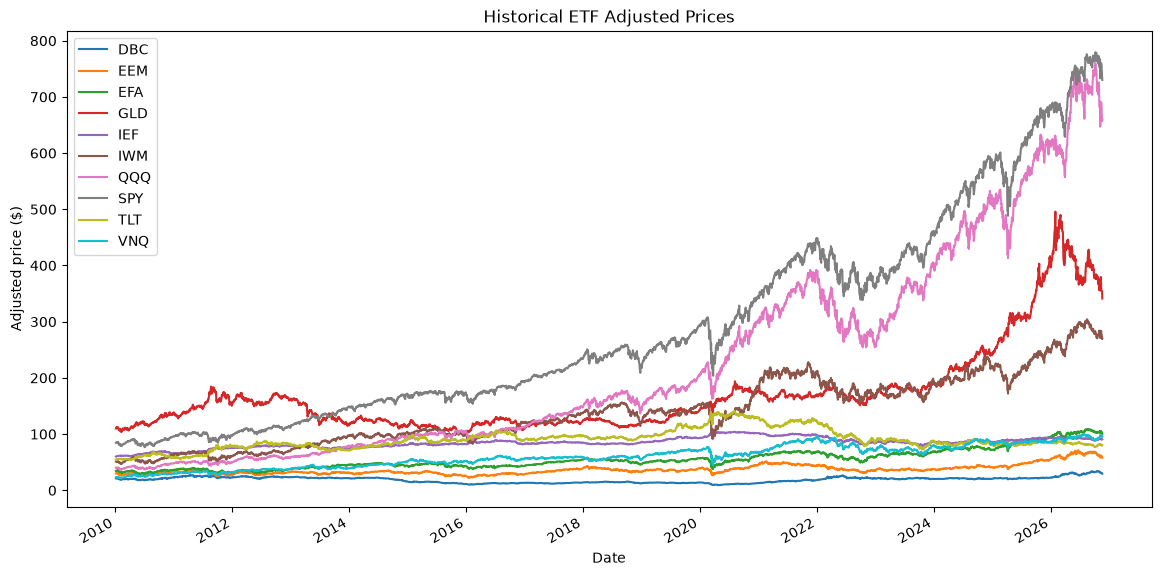

In [16]:
prices.plot(
    figsize=(14, 7),
    title="Historical ETF Adjusted Prices"
)

plt.ylabel("Adjusted price ($)")
plt.show()

In [18]:
returns = prices.pct_change()

returns.describe()

,DBC,EEM,EFA,GLD,IEF,IWM,QQQ,SPY,TLT,VNQ
count,4245.000000,4245.000000,4245.000000,4245.000000,4245.000000,4245.000000,4245.000000,4245.000000,4245.000000,4245.000000
mean,0.000137,0.000247,0.000318,0.000324,0.000105,0.000490,0.000745,0.000566,0.000134,0.000415
std,0.010975,0.013674,0.011535,0.010629,0.004137,0.013941,0.013058,0.010747,0.009369,0.012751
min,-0.079444,-0.124792,-0.109902,-0.102742,-0.025073,-0.132669,-0.119788,-0.109424,-0.066683,-0.177277
25%,-0.005723,-0.006946,-0.005082,-0.004970,-0.002401,-0.006681,-0.004863,-0.003716,-0.005580,-0.005555
50%,0.000650,0.000727,0.000631,0.000521,0.000200,0.001013,0.001171,0.000693,0.000512,0.000779
75%,0.006344,0.007707,0.006312,0.005834,0.002571,0.008118,0.007425,0.005787,0.005698,0.006991
max,0.047990,0.080529,0.084731,0.063587,0.026416,0.091492,0.120031,0.105019,0.075195,0.091039


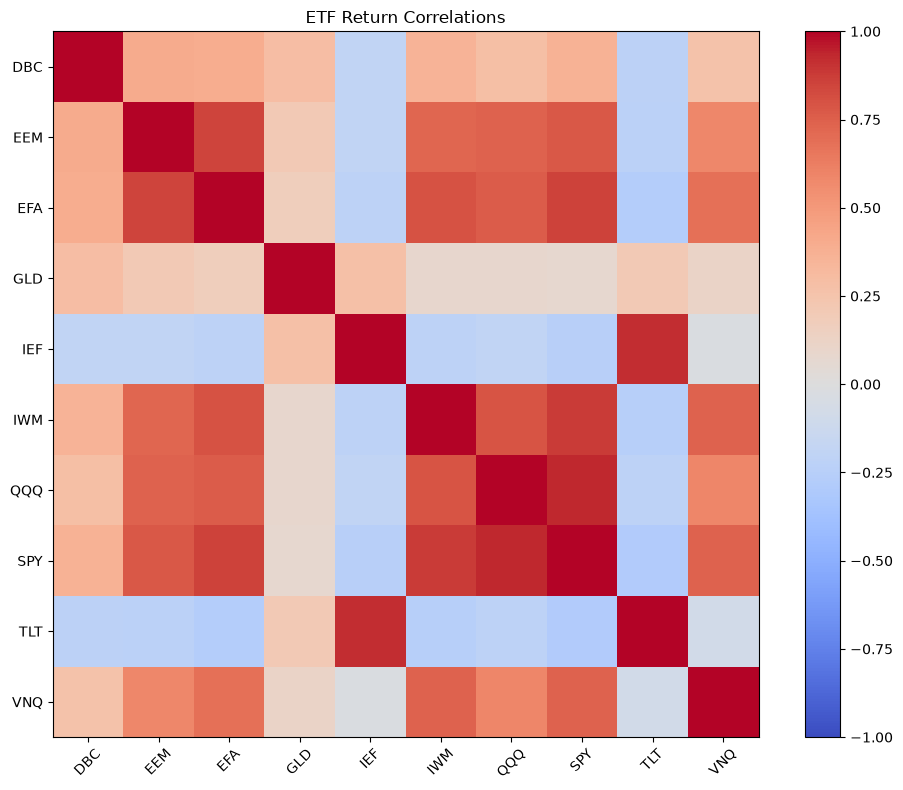

In [20]:
correlation = returns.corr()

plt.figure(figsize=(10, 8))

plt.imshow(
    correlation,
    cmap="coolwarm",
    vmin=-1,
    vmax=1
)

plt.colorbar()
plt.xticks(range(len(correlation)), correlation.columns, rotation=45)
plt.yticks(range(len(correlation)), correlation.columns)

plt.title("ETF Return Correlations")
plt.tight_layout()
plt.show()